   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
Linear Regression | RMSE: 69297.72 | MAE: 50413.43 | R2: 0.6488
Ridge Regre

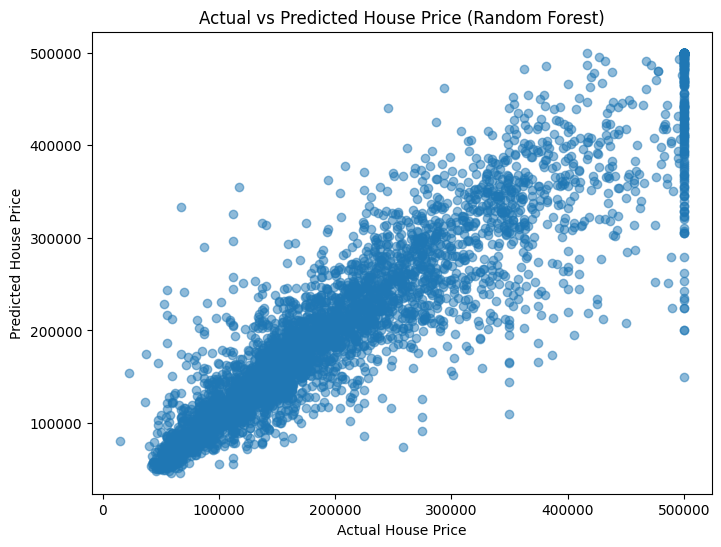

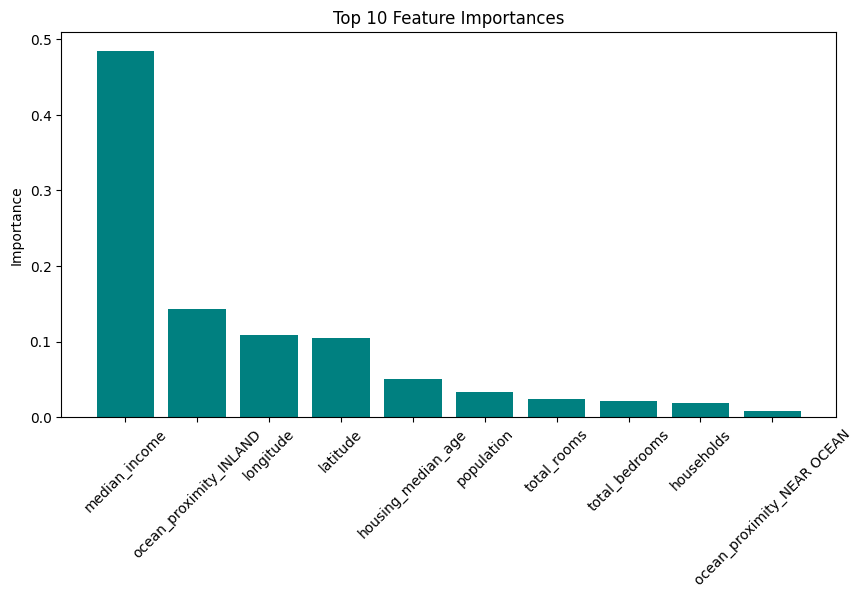

In [2]:
# House Price Prediction with Regression Methods (Corrected Submission-Ready Code)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset (sample from Kaggle, replace with actual path/dataset if needed)
df = pd.read_csv('https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv')

# Preview the data
print(df.head())

# Data preprocessing
df = df.dropna()
df = pd.get_dummies(df, drop_first=True)

# Define features and target
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Model training and evaluation
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Lasso Regression': Lasso(),
    'Random Forest': RandomForestRegressor(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    # Correct RMSE computation for full compatibility
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results[name] = {'RMSE': rmse, 'MAE': mae, 'R2': r2}
    print(f'{name} | RMSE: {rmse:.2f} | MAE: {mae:.2f} | R2: {r2:.4f}')

# Visualization
plt.figure(figsize=(8, 6))
plt.scatter(y_test, models['Random Forest'].predict(X_test), alpha=0.5)
plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual vs Predicted House Price (Random Forest)')
plt.show()

# Feature importance for Random Forest
importances = models['Random Forest'].feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 5))
plt.bar([X.columns[i] for i in indices[:10]], importances[indices[:10]], color='teal')
plt.xticks(rotation=45)
plt.ylabel('Importance')
plt.title('Top 10 Feature Importances')
plt.show()

# Save results for submission
pd.DataFrame(results).T.to_csv('model_performance_summary.csv')
